In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scrublet as scr
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]

In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
from matplotlib import font_manager
font_manager.fontManager.addfont("csv/Helvetica.ttf")
print(font_manager.findfont("Helvetica"))
plt.rcParams["font.sans-serif"] = ["Helvetica"]
plt.rcParams["pdf.fonttype"] = 42

plt.rcParams['savefig.dpi'] = 300

plt.rcParams["axes.grid"] = False
plt.rcParams["pdf.fonttype"] = 42

/nfs/team205/cs42/HSC/HSC_new_to_transfer/csv/Helvetica.ttf


In [5]:
# figure directory
fig_path = 'figure/'
sc.settings.figdir = fig_path

# Download dataset

In [6]:
manifest = pd.read_csv('manifest/sample_manifest_01052026_manuscript.csv')
manifest = manifest.loc[manifest['screen_no']=='poolTF_1',:]

In [7]:
smp_dict = list(manifest['sequence_name'])

In [8]:
smp_dict

['6464STDY15422808',
 '6464STDY15422809',
 '6464STDY15422810',
 '6464STDY15422811']

In [9]:
# check whether all files have been downloaded in matrix folder
DATAFOLDER = '/nfs/team205/cs42/HSC_matrix/'
exist = [x.split('/')[-1] for x in glob.glob(DATAFOLDER+'*')]

if len([x for x in smp_dict if x not in exist])>0:
    print([smp_dict[x][2] for x in smp_dict if x not in exist],'not in matrix folder')

In [10]:
# max_n_count is decided from the web_summary.html plot - the second step is around 200-400 where soup begins 
def read_files(filename, raw_file_path = '/nfs/team205/cs42/HSC_matrix/',
               max_n_count = 200):

    
    path = '%s/%s/'%(raw_file_path,filename)
    adata = sc.read_10x_h5(path+'raw_feature_bc_matrix.h5', gex_only=False)
    
    adata.obs_names = [filename+"-"+x.strip("-1") for x in adata.obs_names]
   
    # define GEX and antibody_capture
    gex = np.array(adata.var['feature_types']=='Gene Expression')
    antibody_capture = np.array(adata.var['feature_types']=='Antibody Capture')
    
    # caculate n_counts / n_genes per cell
    adata.obs['n_counts_GEX'] = np.sum(adata[:,gex].X, axis=1).A1
    adata.obs['n_genes'] = np.sum(adata[:,gex].X>0,axis=1)
    adata.obs['n_counts_antibody_capture'] = np.sum(adata[:,antibody_capture].X, axis=1).A1
    
    # filter cells
    clist = []
    clist.append(np.array(adata.obs['n_counts_GEX'] < max_n_count))
    
    c = np.column_stack(clist).all(axis=1)
    adata = adata[c].copy()
    
    # update manifest onto .obs
    adata.obs['file'] = filename
    adata.obs['sanger_sample_ID'] = manifest.loc[manifest['sequence_name']==filename, 'sanger_sample_ID'].item()
    adata.obs['HSC_days'] = manifest.loc[manifest['sequence_name']==filename, 'HSC days'].item()
    adata.obs['FACS_sort'] = manifest.loc[manifest['sequence_name']==filename, 'FACS_sort'].item()
    
    sc.write('%s_soup'%(filename),adata)

In [11]:
from multiprocessing import Pool

with Pool(10) as p:
    p.map(read_files, [x for x in smp_dict])

/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/sit

# Merge dataset

In [9]:
ad = {}

In [10]:
for filename in smp_dict:
    ad[filename] = sc.read('%s_soup'%(filename))
    ad[filename].var_names_make_unique()

/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/nfs/users/nfs_c/cs42/.conda/envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1776: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [11]:
merged = None;
for key in ad: 
    if merged is None:
        merged = ad[key]
    else:
        merged = merged.concatenate(ad[key], join='outer')

/tmp/ipykernel_3084583/1590458944.py:6: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  merged = merged.concatenate(ad[key], join='outer')
/tmp/ipykernel_3084583/1590458944.py:6: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  merged = merged.concatenate(ad[key], join='outer')
/tmp/ipykernel_3084583/1590458944.py:6: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  merged = merged.concatenate(ad[key], join='outer')


In [12]:
Counter(merged.obs['file'])

Counter({'6464STDY15422808': 1855208,
         '6464STDY15422809': 1838580,
         '6464STDY15422811': 1699203,
         '6464STDY15422810': 1530964})

# Call TF based on barcode

In [13]:
antibody_capture = merged.var_names[merged.var['feature_types']=='Antibody Capture']

In [14]:
#from scipy.sparse import csr_matrix

In [15]:
df_plot = pd.DataFrame()
for key in ad:
    adata = ad[key]
    X = adata[:, antibody_capture].X
    
    # extract non0 entries for plotting
    df = pd.DataFrame({'soup_non0_exp': X.data,
                      'sample': key})
    if df_plot.empty:
        df_plot = df
    else: 
        df_plot = pd.concat([df_plot, df], axis=0)
        
    print(key, 'non-zero%: ', X.nnz/X.shape[0]*100, 'max count: ', np.max(X),'99.9th centile: ',np.percentile(X.data, 99.9))
    print((X > 5).sum() / X.shape[0])

6464STDY15422808 non-zero%:  2.691180719358692 max count:  18.0 99.9th centile:  4.0
1.3475577940586715e-05
6464STDY15422809 non-zero%:  0.44066616628049904 max count:  9.0 99.9th centile:  4.898926
3.263388049472963e-06
6464STDY15422810 non-zero%:  2.6860200501122167 max count:  10.0 99.9th centile:  4.0
7.83819867743461e-06
6464STDY15422811 non-zero%:  1.2608852503202972 max count:  25.0 99.9th centile:  5.0
1.118171283831302e-05


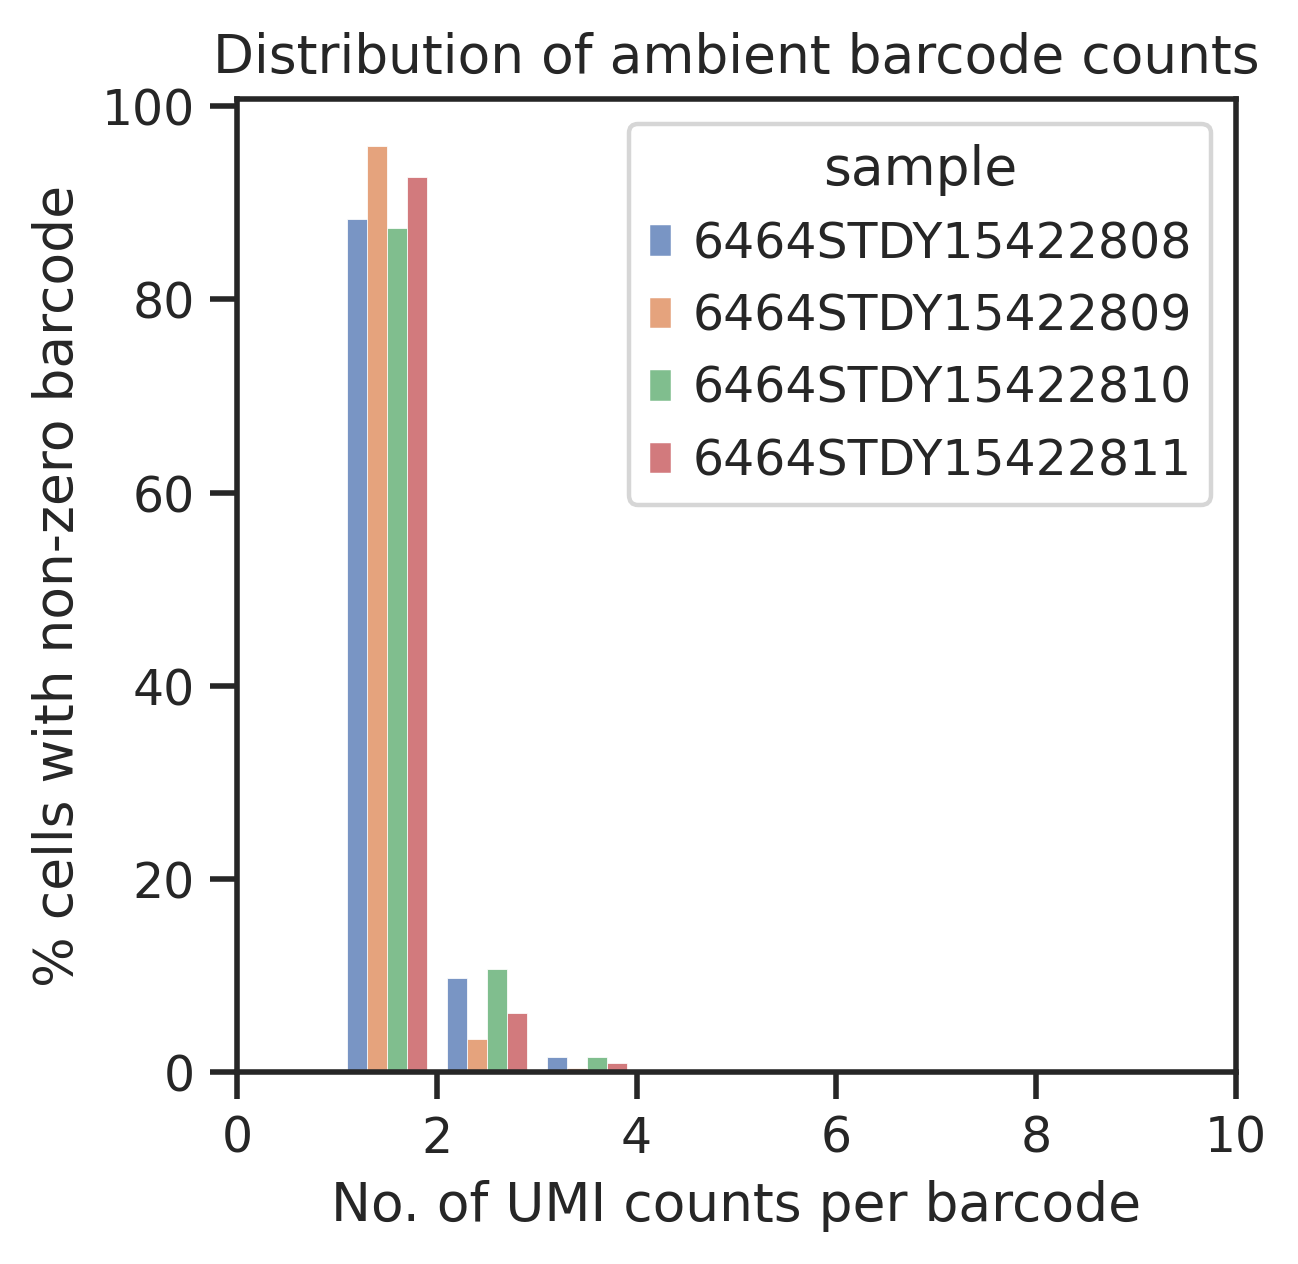

In [16]:
sb.set_theme(style="ticks")

plt.figure(figsize=(4, 4))

ax = sb.histplot(
    data=df_plot,
    x="soup_non0_exp",
    stat="percent",
    hue="sample",
    binwidth=1,
    common_norm=False,
    multiple="dodge",
    shrink=0.8
)

ax.set_xlim(0, 10)
ax.set_xlabel("No. of UMI counts per barcode")
ax.set_ylabel("% cells with non-zero barcode")
ax.set_title("Distribution of ambient barcode counts")

#sb.despine()

plt.savefig(
    "figure/soup_barcode_count_histogram.pdf",
    dpi=300,
    bbox_inches="tight"
)
